In [1]:
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from utils import read_rga_file, get_t0, get_integral

In [4]:
folder = '../rga'

In [5]:
filenames = [
    'PressurevsTime-20261102-171546-393.txt',
]

In [6]:
masses = [87, 28, 40, 62, 84]

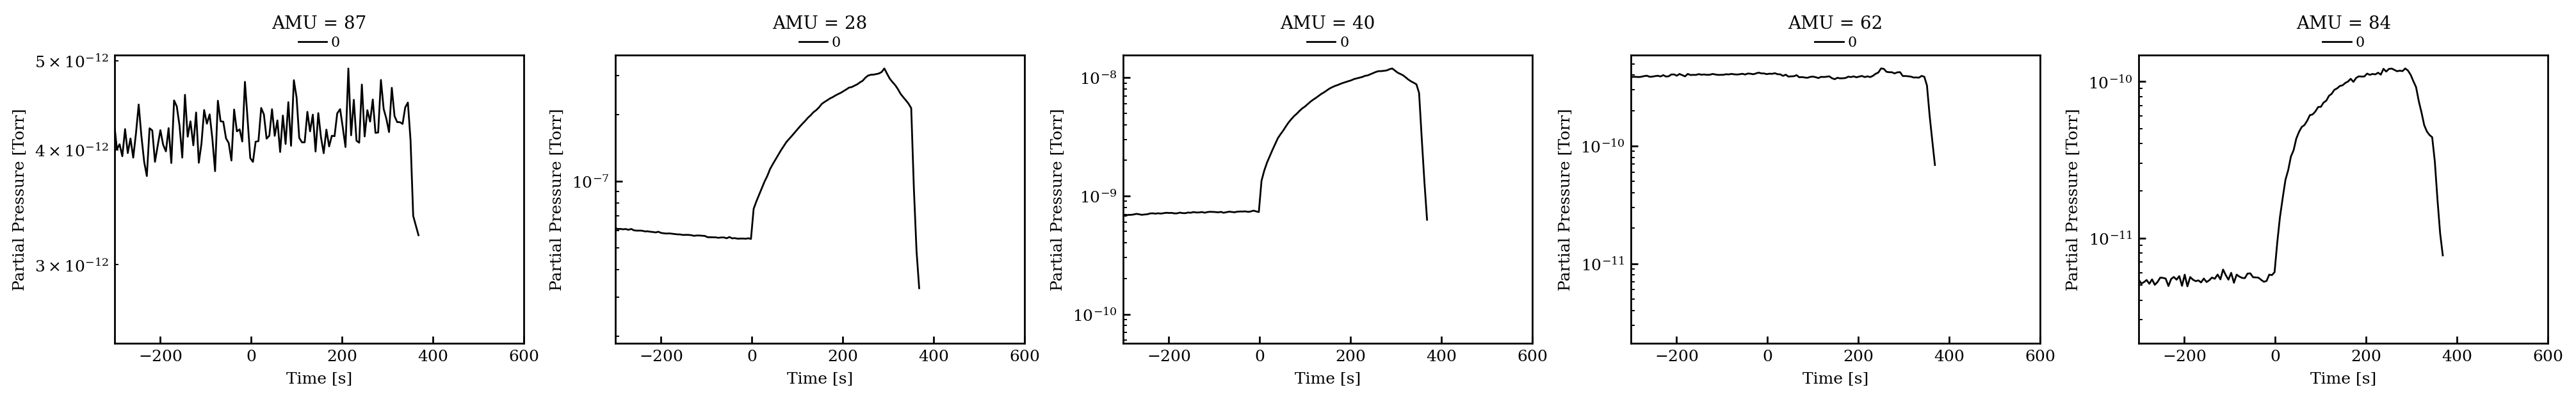

In [7]:
fig, axes = plt.subplots(1, len(masses), figsize=(4 * len(masses), 3))

for i, (ax, mass) in enumerate(zip(axes, masses)):
    for j, filename in enumerate(filenames):
        rga = read_rga_file(os.path.join(folder, filename))
        # filename.split('-')[2]
        t0 = get_t0(rga['t'], rga[28])
        ax.plot(rga['t'] - t0, rga[mass], label=j)
    
    ax.legend(title=f'AMU = {mass}', ncols=len(filenames))
    ax.set_xlabel('Time [s]')
    ax.set_ylabel('Partial Pressure [Torr]')
    ax.set_yscale('log')
    ax.set_xlim(-300, 600)
    
plt.show()

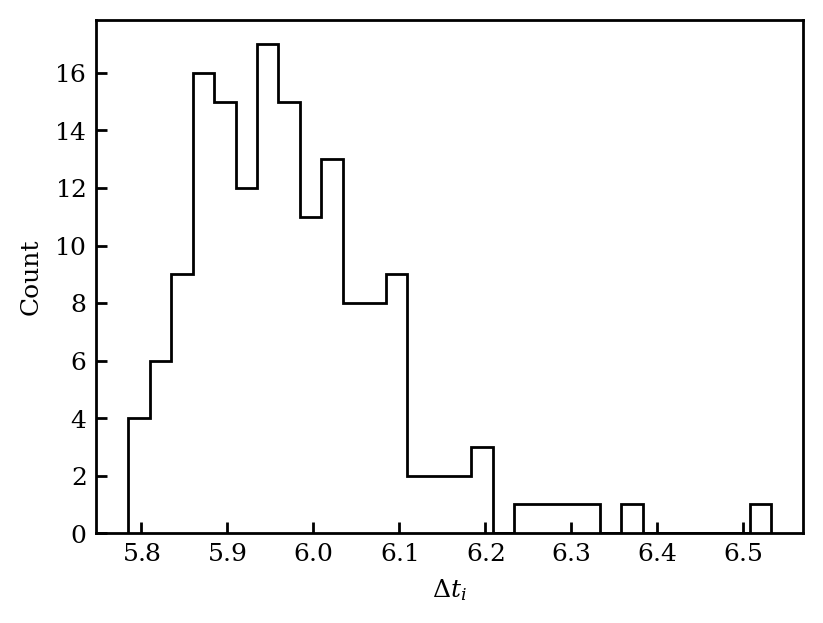

In [8]:
# See whether time intervals are the same

fig, ax = plt.subplots(1, 1, figsize=(4, 3))

ax.hist(np.diff(rga['t']), bins=30, histtype='step')

ax.set_xlabel('$\Delta t_i$')
ax.set_ylabel('Count')

plt.show()

In [9]:
mask = rga['t'] < t0
mask &= rga['t'] > t0 - 300

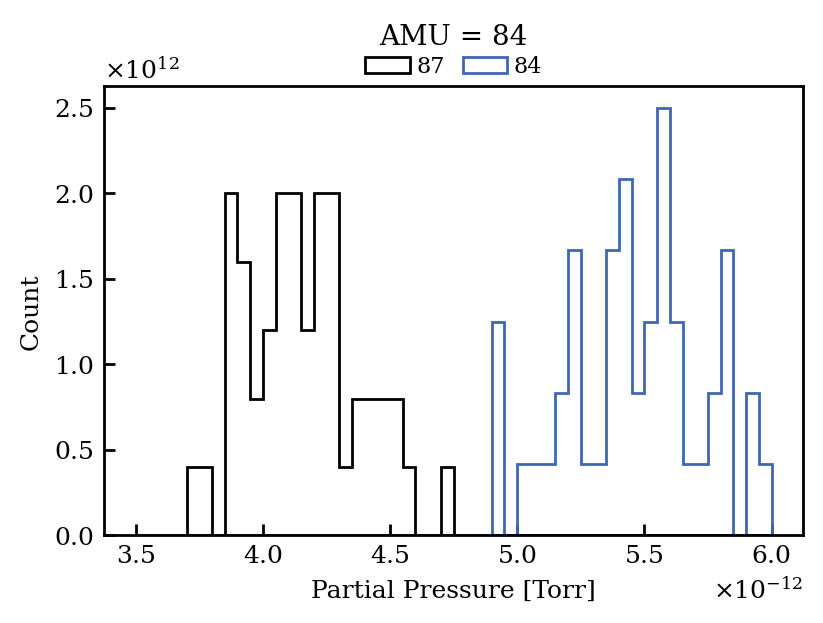

In [10]:
bins = np.linspace(3.5e-12, 6e-12, 51)

fig, ax = plt.subplots(1, 1, figsize=(4, 3))

for j in [87, 84]:
    ax.hist(rga[j][mask], bins=bins, density=True, histtype='step', label=j)

ax.legend(title=f'AMU = {mass}', ncols=len(filenames))
ax.set_xlabel('Partial Pressure [Torr]')
ax.set_ylabel('Count')

plt.show()

In [11]:
N_bkg = mask.sum()

In [12]:
sigma_84 = np.std(rga[84][mask])
sigma_87 = np.std(rga[87][mask])  # sigma_bkg

In [13]:
sigma_84 / sigma_87

np.float64(1.352453676339113)

In [14]:
c = (sigma_84 / sigma_87 - 1) / (np.mean(rga[84][mask]) - np.mean(rga[87][mask]))

In [15]:
c / 1e12  # pTorr^-1

np.float64(0.2634080561436424)

In [16]:
xmin, xmax = -10, 250
mask = (rga['t'] > t0 + xmin) & (rga['t'] < t0 + xmax)

In [17]:
N_flw = mask.sum()

In [18]:
P_flw_84 = np.mean(rga[84][mask]) - np.mean(rga[87][mask])

In [19]:
max_P_flw_84 = rga[84][mask].max()

In [20]:
N_bkg, N_flw, P_flw_84

(np.int64(50), np.int64(44), np.float64(7.032018409090911e-11))

In [21]:
c * P_flw_84

np.float64(18.522902999049457)

In [22]:
sigma_87 * 2 ** 0.5 * ((1 + c * P_flw_84) / N_flw + 1 / N_bkg) ** 0.5

np.float64(2.1230940647619216e-13)

In [23]:
sigma_87 * ((c * P_flw_84) ** 2 / N_flw) ** 0.5

np.float64(6.156265033797528e-13)

In [24]:
lower = lambda x: sigma_87 * 2 ** 0.5 * ((1 + c * x) / N_flw + 1 / N_bkg) ** 0.5

# upper = lambda x: sigma_87 * ((c * x) ** 2 / N_flw) ** 0.5
upper = lambda x: sigma_87 * ((c * x / P_flw_84 * max_P_flw_84) ** 2 / N_flw) ** 0.5

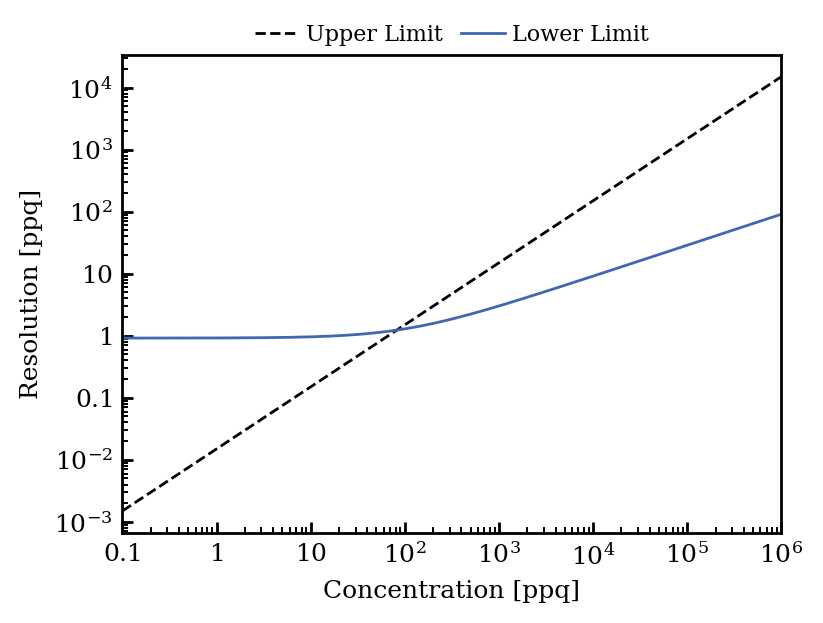

In [25]:
x = np.geomspace(1e-4 * P_flw_84, 1e3 * P_flw_84, 1001)

fig, ax = plt.subplots(1, 1, figsize=(4, 3))

ax.plot(x / P_flw_84 * 1e3, upper(x) / P_flw_84 * 1e3, label='Upper Limit', linestyle='dashed')
ax.plot(x / P_flw_84 * 1e3, lower(x) / P_flw_84 * 1e3, label='Lower Limit')

ax.legend()
# ax.set_xlabel('Mean Partial Pressure [Torr]')
ax.set_xlabel('Concentration [ppq]')
ax.set_ylabel('Resolution [ppq]')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(x[0] / P_flw_84 * 1e3, x[-1] / P_flw_84 * 1e3)

plt.show()

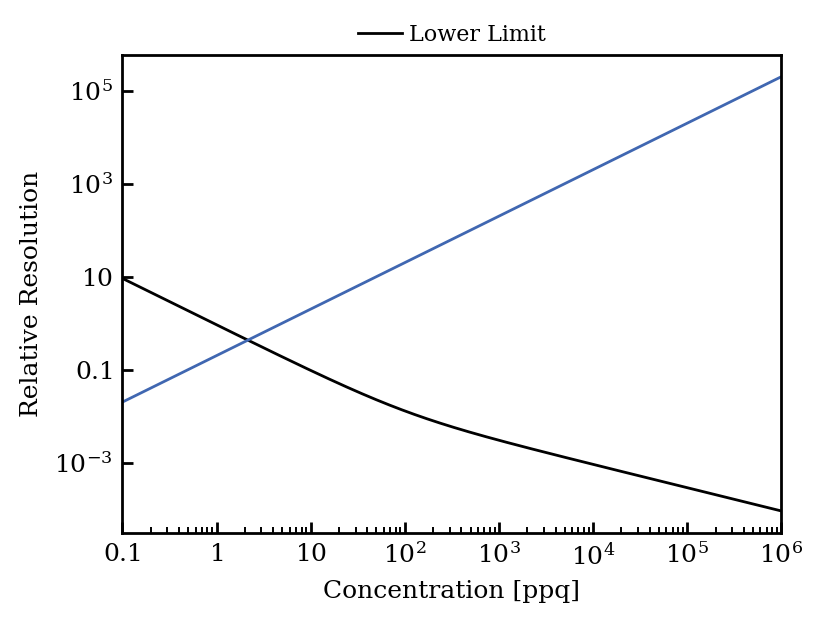

In [26]:
x = np.geomspace(1e-4 * P_flw_84, 1e3 * P_flw_84, 1001)

fig, ax = plt.subplots(1, 1, figsize=(4, 3))

ax.plot(x / P_flw_84 * 1e3, lower(x) / x, label='Lower Limit')
# ax.plot(x / P_flw_84 * 1e3, upper(x) / x, label='Upper Limit')
ax.plot(x / P_flw_84 * 1e3, x / P_flw_84 * 1e3 / 5)

ax.legend()
# ax.set_xlabel('Mean Partial Pressure [Torr]')
ax.set_xlabel('Concentration [ppq]')
ax.set_ylabel('Relative Resolution')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(x[0] / P_flw_84 * 1e3, x[-1] / P_flw_84 * 1e3)

plt.show()